**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: Joshua Gamboa Calvo
*   MATRÍCULA: A01841021

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [120]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [121]:
loan_df = pd.read_csv("personal_loan.csv")
loan_df.head()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,0,25,1,49,91108,4,1.6,1.0,0,0,Yes,No,0,0
1,1,45,19,34,90089,3,1.5,1.0,0,No,Yes,No,No,0
2,2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,3,35,9,100,94112,1,2.7,2.0,0,0,0,0,No,0
4,4,35,8,45,91330,4,1.0,2.0,0,0,No,No,0,1


In [122]:
loan_df = loan_df.set_index("ID")
loan_df.head()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
0,25,1,49,91108,4,1.6,1.0,0,0,Yes,No,0,0
1,45,19,34,90089,3,1.5,1.0,0,No,Yes,No,No,0
2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2.0,0,0,0,0,No,0
4,35,8,45,91330,4,1.0,2.0,0,0,No,No,0,1


In [123]:
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


### ¿Cuántas columnas son numéricas y cuántas de texto?

Dado el analísis en la columna anterior, se tiene que 8 columnas son numbericas (2 punto flotante y 6 enteras) y 5 eran texto. Cabe aclarar, que segun la definición de los datos en este cuaderno se identifican varias inconsistencias como las siguientes:

- La columna de `Education` es de tipo punto flotante aunque sus valores defindos son enteros.
- Las 5 columnas de tipo `object` o texto, deberian ser numericas. Ya que representan booleanos y solo deberian tomar el valor de 0 y 1.

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [124]:
loan_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,5037.0,45.411356,11.646805,23.0,35.0,45.0,55.0,144.0
Experience,5037.0,20.122494,11.461278,-3.0,10.0,20.0,30.0,43.0
Income,5037.0,73.898352,46.130504,8.0,39.0,64.0,98.0,224.0
ZIP Code,5037.0,93152.865595,2119.637960,9307.0,91911.0,93437.0,94608.0,96651.0
Family,5037.0,2.394679,1.151145,-3.0,1.0,2.0,3.0,4.0
CCAvg,5037.0,1.942404,1.755954,0.0,0.7,1.5,2.6,10.0
Education,5037.0,1.880941,0.843337,1.0,1.0,2.0,3.0,7.3
Mortgage,5037.0,56.500695,101.657580,0.0,0.0,0.0,101.0,635.0


In [125]:
tamano_inicial = len(loan_df)

### Decisión: Age mayor a 100

Los registros con edad superior a 100 años (123, 130 y 140; ajusta esta lista con los valores reales de tu salida) se eliminan por no ser plausibles.

**Justificación:** la edad humana más alta documentada es de aproximadamente 122 años, por lo que valores como 130 o 140 son imposibles y corresponden a errores de captura. No es posible conocer la edad real, así que no se pueden corregir ni imputar de forma confiable. Mantenerlos distorsionaría la media, la desviación estándar y cualquier modelo que use `Age`.

Adicionalmente, aun suponiendo que fueran personas reales de edad muy avanzada, representarían un perfil atípico para un préstamo personal, con mayor riesgo de impago por fallecimiento, lo que refuerza la decisión de excluirlos del análisis.

In [126]:
loan_df[loan_df["Age"] > 100]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


In [127]:
loan_df = loan_df[loan_df["Age"] <= 100]
loan_df

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
0,25,1,49,91108,4,1.6,1.0,0,0,Yes,No,0,0
1,45,19,34,90089,3,1.5,1.0,0,No,Yes,No,No,0
2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2.0,0,0,0,0,No,0
4,35,8,45,91330,4,1.0,2.0,0,0,No,No,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5032,34,9,65,95134,4,1.3,1.0,0,0,No,No,No,Yes
5033,45,20,84,94131,4,1.1,2.0,180,0,No,0,1,0
5034,47,23,148,94551,2,7.5,1.0,0,0,No,1,Yes,Yes


### Decisión: Experience negativa

Los registros con `Experience` menor a 0 (valor mínimo observado: -3; ajusta con tu salida) se eliminan por ser inválidos.

**Justificación:** la experiencia laboral se mide en años trabajados, por lo que no puede ser negativa. Podría tratarse de un error de signo (por ejemplo, -3 en lugar de 3), pero asumirlo sería inventar un dato sin evidencia que lo respalde. Como no es posible conocer el valor real, no se corrige ni se imputa. Conservarlos distorsionaría la media y la relación entre `Experience` y `Age`.

In [128]:
exp_neg = loan_df[loan_df["Experience"] < 0]
print(f"Registros con Experience < 0: {len(exp_neg)}")
exp_neg.head()

Registros con Experience < 0: 53


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
89,25,-1,113,94303,4,2.30,3.0,0,No,No,0,No,Yes
226,24,-1,39,94085,2,1.70,2.0,0,0,No,0,No,0
315,24,-2,51,90630,3,0.30,3.0,0,0,No,No,1,0
451,28,-2,48,94132,2,1.75,3.0,89,0,No,0,1,No
524,24,-1,75,93014,4,0.20,1.0,0,0,No,No,Yes,0


In [129]:
n_antes = len(loan_df)
loan_df = loan_df[loan_df["Experience"] >= 0]
print(f"Eliminados: {n_antes - len(loan_df)} | Restantes: {len(loan_df)}")

Eliminados: 53 | Restantes: 4981


### Registro: No Experience mayor que Age

No se identificaron ocurrencias donde Age fuera menor Experience, por lo que no se aplico nunca transformacion.

In [130]:
exp_mayor_edad = loan_df[loan_df["Experience"] > loan_df["Age"]]
print(f"Registros con Experience > Age: {len(exp_mayor_edad)}")
exp_mayor_edad.head()

Registros con Experience > Age: 0


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,


### Decisión: ZIP Code incompleto

Los registros con `ZIP Code` de menos de 5 dígitos (valor observado: 9307) se eliminan por estar truncados.

**Justificación:** los códigos postales de EE. UU. tienen 5 dígitos. Un valor de 4 dígitos indica que falta un dígito, y no se puede saber cuál era (podría ser 09307 o un dígito perdido en otra posición). Como el dato original no es recuperable, no se corrige. Mantenerlo introduciría una ubicación falsa en cualquier análisis geográfico.

In [131]:
zip_corto = loan_df[loan_df["ZIP Code"] < 10000]
print(f"Registros con ZIP Code de menos de 5 dígitos: {len(zip_corto)}")
zip_corto.head()

Registros con ZIP Code de menos de 5 dígitos: 1


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
384,51,25,21,9307,4,0.6,3.0,0,No,0,0,1,Yes


In [132]:
n_antes = len(loan_df)
loan_df = loan_df[loan_df["ZIP Code"] >= 10000]
print(f"Eliminados: {n_antes - len(loan_df)} | Restantes: {len(loan_df)}")

Eliminados: 1 | Restantes: 4980


### Decisión: Family negativa

Los registros con `Family` menor a 1 (valor mínimo observado: -3) se eliminan por ser inválidos.

**Justificación:** el número de miembros de la familia no puede ser negativo, y como el cliente forma parte de su propio hogar, el mínimo lógico es 1. Un valor de -3 es un error de captura. Aunque podría ser un error de signo, no se puede confirmar si el valor real era 3, así que no se imputa. Conservarlo sesgaría las estadísticas de tamaño de hogar.

In [133]:
fam_invalida = loan_df[loan_df["Family"] < 1]
print(f"Registros con Family < 1: {len(fam_invalida)}")
fam_invalida.head()

Registros con Family < 1: 2


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
15,60,30,22,95054,-1,1.5,3.0,0,0,No,0,Yes,Yes
3000,40,14,164,94720,-3,4.3,2.0,0,1,No,No,No,No


In [134]:
n_antes = len(loan_df)
loan_df = loan_df[loan_df["Family"] >= 1]
print(f"Eliminados: {n_antes - len(loan_df)} | Restantes: {len(loan_df)}")

Eliminados: 2 | Restantes: 4978


### Decisión: Education fuera de categorías válidas

Los registros con `Education` distinta de 1, 2 o 3 (valor máximo observado: 7.3) se eliminan por estar fuera del dominio de la variable.

**Justificación:** según el diccionario de datos, `Education` es una variable categórica con solo tres niveles (1 = graduado, 2 = universitario, 3 = posgrado). Un valor como 7.3 no corresponde a ninguna categoría y ni siquiera es entero, lo que indica un error de captura. No hay una categoría válida a la cual asignarlo, así que se elimina. Dejarlo crearía una categoría inexistente al codificar la variable para el modelo. Adicionalmente, debido a que ya se identifico que los unicos valores que puede tomar esta variable es un entero, se va a transformar el dtype de esta columna

In [135]:
edu_invalida = loan_df[~loan_df["Education"].isin([1, 2, 3])]
print(f"Registros con Education fuera de {{1, 2, 3}}: {len(edu_invalida)}")
edu_invalida.head()

Registros con Education fuera de {1, 2, 3}: 1


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
347,25,0,43,94305,2,1.6,7.3,0,0,Yes,Yes,1,Yes


In [136]:
n_antes = len(loan_df)
loan_df = loan_df[loan_df["Education"].isin([1, 2, 3])]
print(f"Eliminados: {n_antes - len(loan_df)} | Restantes: {len(loan_df)}")

Eliminados: 1 | Restantes: 4977


In [137]:
n_final = len(loan_df)
eliminados = tamano_inicial - n_final
porcentaje = eliminados / tamano_inicial * 100

print(f"Registros iniciales: {tamano_inicial}")
print(f"Registros finales:   {n_final}")
print(f"Eliminados en total: {eliminados}")
print(f"Porcentaje eliminado: {porcentaje:.2f}%")

Registros iniciales: 5037
Registros finales:   4977
Eliminados en total: 60
Porcentaje eliminado: 1.19%


In [138]:
loan_df['Education'] = loan_df['Education'].astype(int)
loan_df['Education'].dtype

dtype('int64')

### ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

Basado en la celda anterior, tenemos que se eliminaron `60` registros lo cual representa un `1.19%` del dataframe inicial.

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [139]:
cols_texto = loan_df.select_dtypes(include=["object", "string"]).columns
print("Columnas de texto:", list(cols_texto))

loan_df[cols_texto].describe().T

Columnas de texto: ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


,count,unique,top,freq
Personal Loan,4977,4,0,3475
Securities Account,4977,4,No,2693
CD Account,4977,4,No,2462
Online,4977,4,Yes,1700
CreditCard,4977,4,0,2628


In [140]:
cols_binarias = ["Personal Loan", "Securities Account", "CD Account", "Online", "CreditCard"]

for col in cols_binarias:
    print(f"--- {col} ---")
    print(loan_df[col].value_counts(dropna=False))
    print()

--- Personal Loan ---
Personal Loan
0      3475
No     1017
Yes     368
1       117
Name: count, dtype: int64

--- Securities Account ---
Securities Account
No     2693
0      1765
Yes     390
1       129
Name: count, dtype: int64

--- CD Account ---
CD Account
No     2462
0      2212
1       163
Yes     140
Name: count, dtype: int64

--- Online ---
Online
Yes    1700
No     1628
1      1275
0       374
Name: count, dtype: int64

--- CreditCard ---
CreditCard
0      2628
Yes     907
No      885
1       557
Name: count, dtype: int64



### Decisión: Unificar los valores binarios a 0 y 1

Se reemplaza `Yes` por **1** y `No` por **0**, y se convierten las columnas a tipo entero.

**Justificación:** el diccionario de datos define estas variables como indicadores con 1 = sí y 0 = no. Con formatos mezclados, una misma categoría se contaría como dos distintas (por ejemplo, `Yes` y `1`), lo que sesgaría las frecuencias e impediría usar las columnas en un modelo, que requiere valores numéricos consistentes.

In [141]:
mapeo = {"1": 1, "0": 0, "Yes": 1, "No": 0}

for col in cols_binarias:
    loan_df[col] = loan_df[col].astype(str).str.strip().map(mapeo)

# Verificar que no quedaron nulos por valores sin mapear
print(loan_df[cols_binarias].isna().sum())

Personal Loan         0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
dtype: int64


In [142]:
loan_df[cols_binarias] = loan_df[cols_binarias].astype(int)
loan_df.head()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
0,25,1,49,91108,4,1.6,1,0,0,1,0,0,0
1,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [145]:
# Duplicados considerando solo el contenido de las columnas
dup_contenido = loan_df.duplicated(keep=False)
print("Filas con contenido idéntico:", dup_contenido.sum())

Filas con contenido idéntico: 72


### Decisión: Eliminar registros duplicados

Se eliminan los registros duplicados conservando la primera aparición de cada uno.

**Justificación:** un registro repetido representa al mismo cliente contado más de una vez. Mantener las copias le daría más peso a ese cliente en las estadísticas y en el modelo, y sesgaría las frecuencias de las variables, incluida la variable objetivo `Personal Loan`. Con 13 columnas (ingreso, edad, código postal, etc.), es altamente improbable que dos clientes distintos coincidan en todos los valores, por lo que las filas idénticas se consideran copias y no clientes diferentes. Si el resultado fuera 0, se documenta que se verificó y no fue necesario eliminar nada.

In [148]:
loan_df = loan_df.drop_duplicates(keep="first")
loan_df.head()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
0,25,1,49,91108,4,1.6,1,0,0,1,0,0,0
1,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


### Decisión: Reiniciar el índice

Tras todas las eliminaciones realizadas en los ejercicios anteriores, el índice tiene saltos en su secuencia. Se reinicia para que quede continuo, de 0 a n-1.

**Justificación:** un índice con huecos dificulta recorrer o dividir el dataframe por posición y puede causar confusión al verificar cuántos registros quedan. Reiniciarlo deja una numeración limpia y consistente con el número real de registros.

In [149]:
loan_df = loan_df.reset_index(drop=True)
loan_df.head()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,25,1,49,91108,4,1.6,1,0,0,1,0,0,0
1,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [150]:
loan_df["ZIP Code"] = loan_df["ZIP Code"].astype(str)
loan_df["Education"] = pd.Categorical(loan_df["Education"].astype(int), categories=[1, 2, 3], ordered=True)

cols_binarias = ["Personal Loan", "Securities Account", "CD Account", "Online", "CreditCard"]
loan_df[cols_binarias] = loan_df[cols_binarias].astype("category")

loan_df.dtypes

,0
Age,int64
Experience,int64
Income,int64
ZIP Code,object
Family,int64
CCAvg,float64
Education,category
Mortgage,int64
Personal Loan,category
Securities Account,category


In [151]:
num_cols = loan_df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = loan_df.select_dtypes(include=["object", "category"]).columns.tolist()

print("num_cols:", num_cols)
print("cat_cols:", cat_cols)

num_cols: ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
cat_cols: ['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [152]:
desc = loan_df[num_cols].describe().T
desc["skew"] = loan_df[num_cols].skew()
desc["kurt"] = loan_df[num_cols].kurt()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurt
Age,4941.0,45.56,11.32,24.0,36.0,46.0,55.0,67.0,-0.02,-1.16
Experience,4941.0,20.34,11.31,0.0,11.0,20.0,30.0,43.0,-0.02,-1.13
Income,4941.0,73.83,46.11,8.0,39.0,64.0,98.0,224.0,0.84,-0.05
Family,4941.0,2.39,1.15,1.0,1.0,2.0,3.0,4.0,0.16,-1.40
CCAvg,4941.0,1.94,1.75,0.0,0.7,1.5,2.6,10.0,1.59,2.64
Mortgage,4941.0,56.66,101.88,0.0,0.0,0.0,101.0,635.0,2.10,4.76


### Clasificación según asimetría y curtosis

Se usan como criterios: asimetría entre -0.5 y 0.5 = aproximadamente simétrica, entre 0.5 y 1 = moderada, mayor a 1 = fuerte; y curtosis en exceso cercana a 0 = mesocúrtica, mayor a 0 = leptocúrtica, menor a 0 = platicúrtica.

- **`Age` (asimetría = -0.02, curtosis = -1.16):** distribución simétrica, con la media (45.56) casi igual a la mediana (46). La curtosis negativa indica que es platicúrtica: más aplanada que una normal, con colas ligeras y sin concentración marcada alrededor de un valor. Los clientes se reparten de forma bastante uniforme entre los 24 y los 67 años.

- **`Income` (asimetría = 0.84, curtosis = -0.05):** asimetría positiva moderada. La media (73.83) supera a la mediana (64) porque hay una cola hacia ingresos altos (máximo 224). La curtosis es prácticamente 0, por lo que es mesocúrtica: las colas y el pico son similares a los de una normal.

- **`Mortgage` (asimetría = 2.10, curtosis = 4.76):** asimetría positiva fuerte y leptocúrtica. La mediana y el percentil 75 son 0 y 101, mientras que el máximo es 635 y la media es 56.66, lo que indica que la mayoría de los clientes no tiene hipoteca y unos pocos tienen montos muy altos. La curtosis positiva confirma colas pesadas y valores extremos frecuentes.

**Implicación para el EDA:** `Age` puede analizarse con medidas basadas en la media. `Income` es aceptable, aunque conviene apoyarse también en la mediana. `Mortgage` requiere la mediana y los cuantiles en lugar de la media, y conviene considerar una transformación (por ejemplo logarítmica) o un tratamiento especial para el grupo con hipoteca igual a 0.

7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

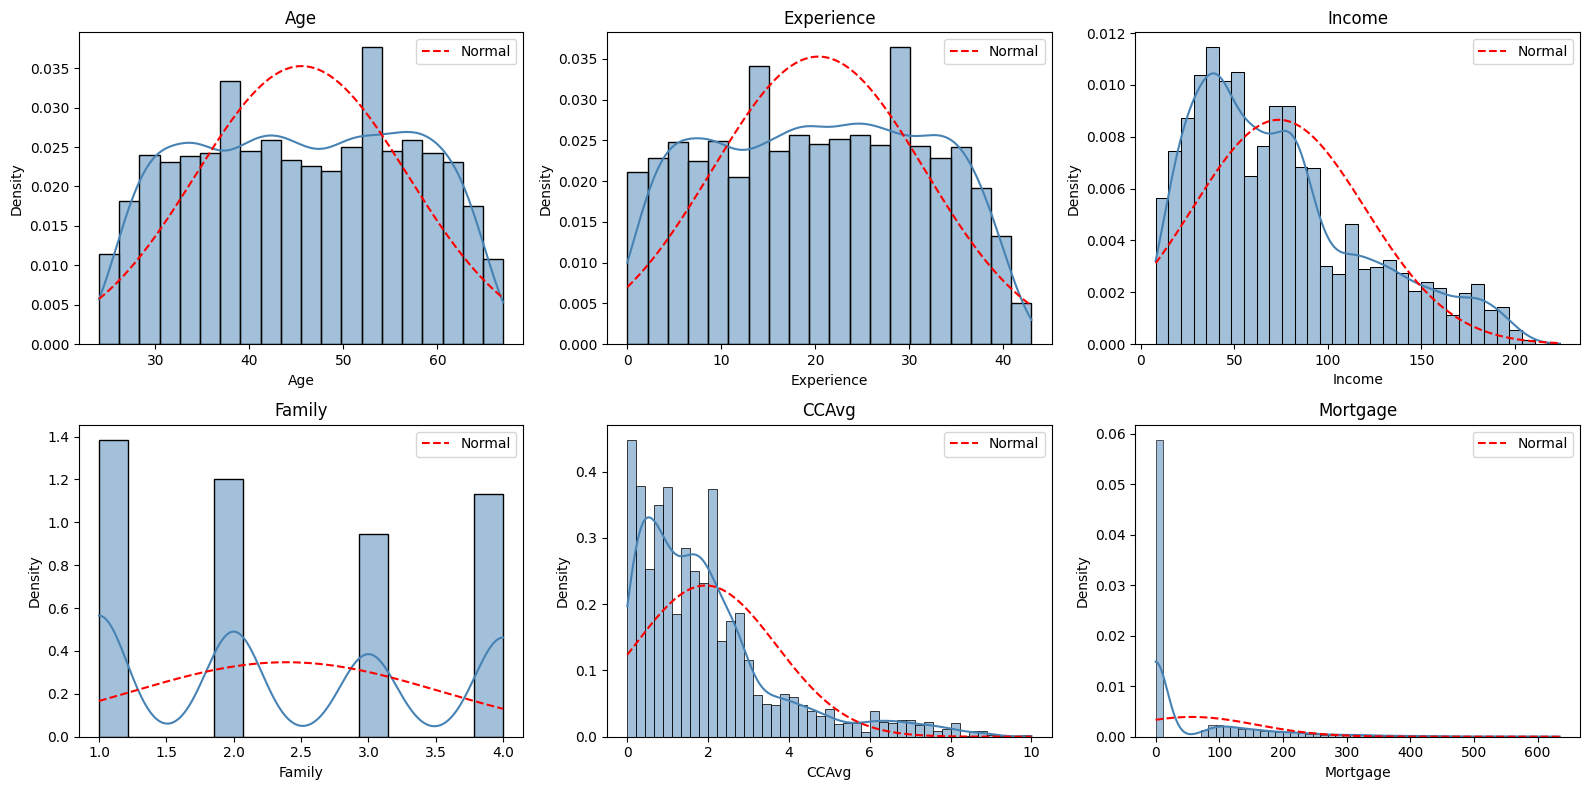

In [153]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(loan_df[col], stat="density", kde=True, ax=ax, color="steelblue")
    x = np.linspace(loan_df[col].min(), loan_df[col].max(), 200)
    ax.plot(x, norm.pdf(x, loan_df[col].mean(), loan_df[col].std()), "r--", label="Normal")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

### Comparación de los histogramas con los valores calculados

- **`Age` (asimetría = -0.02, curtosis = -1.16):** el histograma es aproximadamente simétrico alrededor de los 45-46 años, pero no tiene forma de campana: las barras son casi del mismo alto entre los 30 y los 60 años, con una distribución casi uniforme. La curva KDE es plana y queda por debajo de la normal en el centro y por encima en los extremos. Esto coincide con la curtosis negativa (platicúrtica) y con la asimetría cercana a 0.

- **`Income` (asimetría = 0.84, curtosis = -0.05):** el pico está desplazado a la izquierda (entre 30 y 50 mil USD) y hay una cola larga hacia la derecha, hasta 224. La curva normal queda centrada en la media (73.83), a la derecha del pico real, lo que evidencia la asimetría positiva moderada. Las colas no son notablemente más pesadas que las de la normal, lo que coincide con una curtosis cercana a 0 (mesocúrtica).

- **`Mortgage` (asimetría = 2.10, curtosis = 4.76):** hay una barra enorme en 0 (la mayoría de los clientes no tiene hipoteca) y una cola larga y delgada hasta 635. La normal no se parece en nada a la distribución real. Coincide con la asimetría positiva fuerte y la curtosis alta (leptocúrtica).

**Conclusión:** en las tres variables clasificadas, la forma observada coincide con lo esperado según la asimetría y la curtosis.

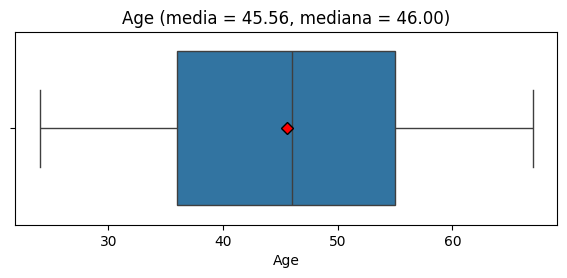

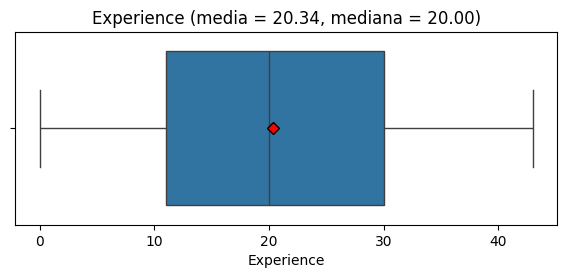

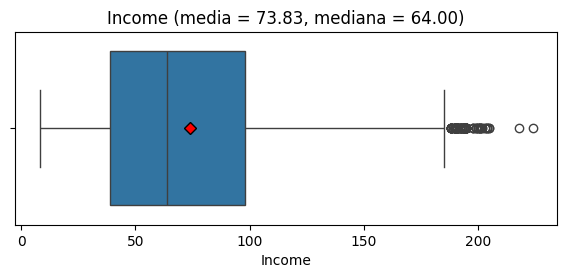

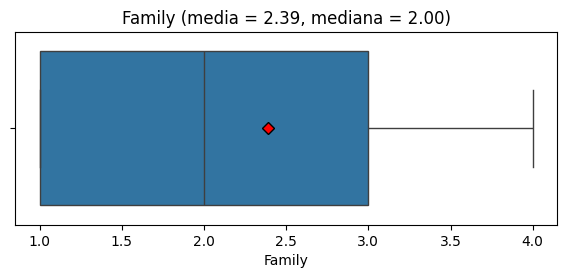

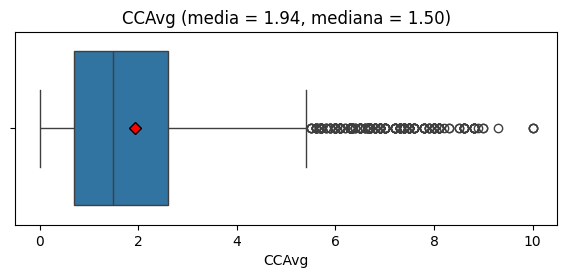

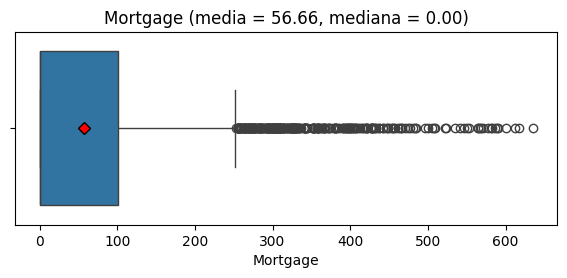

In [154]:
for col in num_cols:
    plt.figure(figsize=(7, 2.5))
    sns.boxplot(x=loan_df[col], showmeans=True,
                meanprops={"marker": "D", "markerfacecolor": "red", "markeredgecolor": "black"})
    plt.title(f"{col} (media = {loan_df[col].mean():.2f}, mediana = {loan_df[col].median():.2f})")
    plt.show()

###  ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

La relación entre la media y la mediana indica el sentido del sesgo. Si la media es mayor que la mediana, la distribución tiene asimetría positiva: unos pocos valores altos jalan la media hacia la derecha, mientras que la mediana, que es robusta a los extremos, casi no se mueve. Si son casi iguales, la distribución es simétrica. Si la media fuera menor que la mediana, el sesgo sería negativo.

| Variable | Media | Mediana | Relación | Sesgo |
|---|---|---|---|---|
| `Age` | 45.56 | 46 | Casi iguales | Simétrica |
| `Experience` | 20.34 | 20 | Casi iguales | Simétrica |
| `Income` | 73.83 | 64 | Media > mediana (≈ 10 puntos) | Positivo moderado |
| `Family` | 2.39 | 2 | Media ligeramente > mediana | Positivo leve |
| `CCAvg` | 1.94 | 1.5 | Media > mediana | Positivo fuerte |
| `Mortgage` | 56.66 | 0 | Media muy por encima de la mediana | Positivo muy fuerte |

**Conclusión:** en todas las variables con asimetría positiva la media es mayor que la mediana, y la diferencia crece con la intensidad del sesgo (`Income` < `CCAvg` < `Mortgage`). En las variables sesgadas conviene resumir con la mediana y los cuantiles en lugar de la media, porque la media se ve inflada por los valores extremos.

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [155]:
loan_df[cat_cols].describe().T

,count,unique,top,freq
ZIP Code,4941,467,94720,163
Education,4941,3,1,2079
Personal Loan,4941,2,0,4462
Securities Account,4941,2,0,4426
CD Account,4941,2,0,4640
Online,4941,2,1,2951
CreditCard,4941,2,0,3489


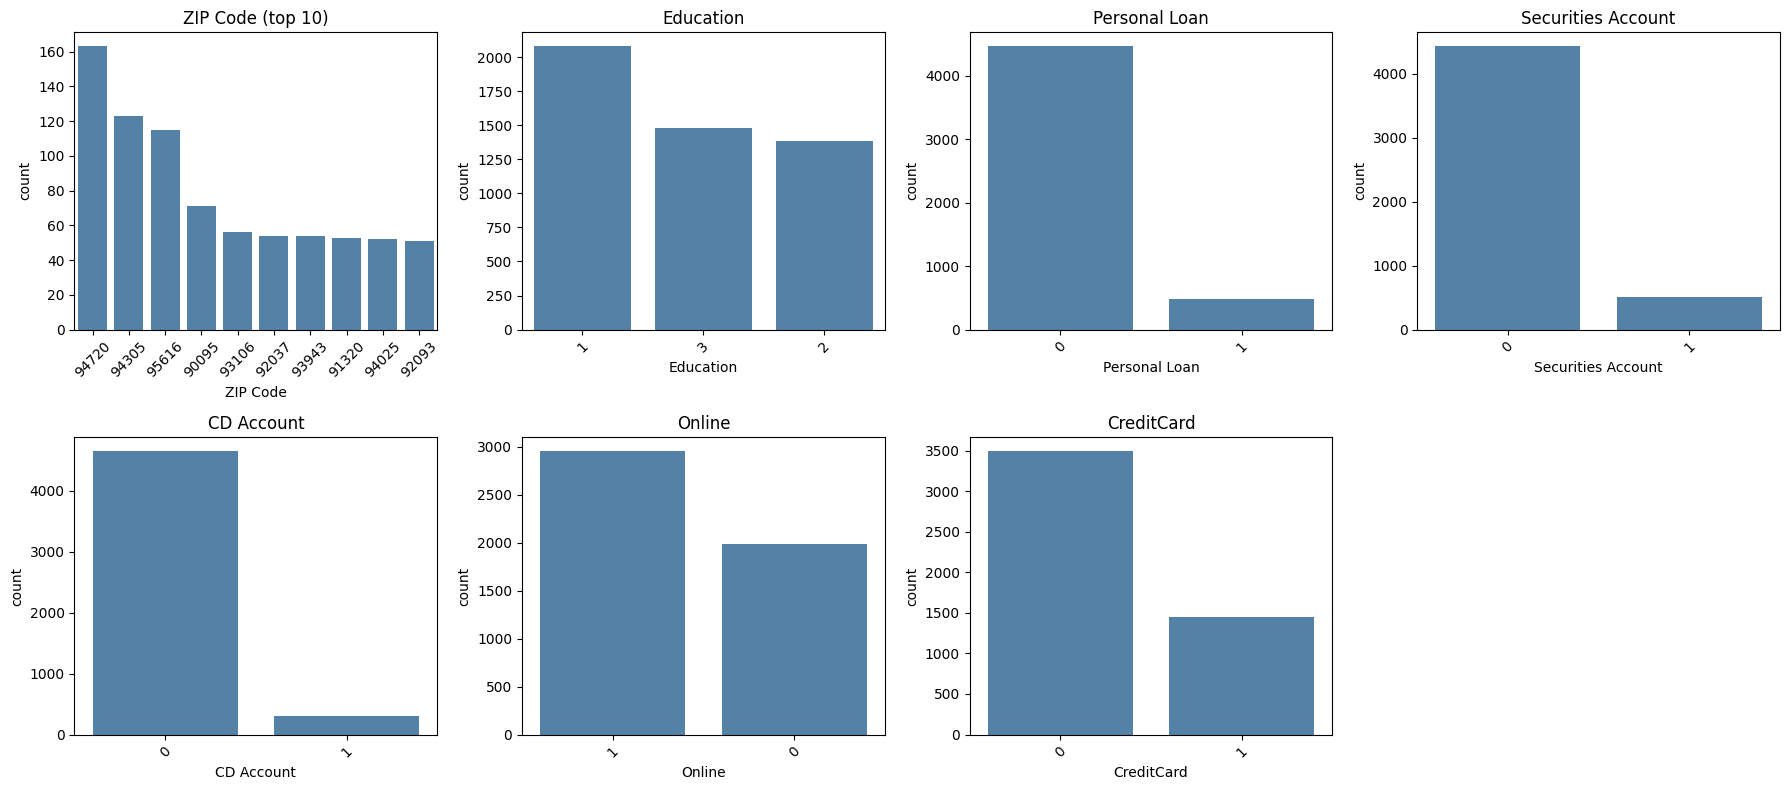

In [156]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    orden = loan_df[col].value_counts().head(10).index
    sns.countplot(x=loan_df[col], order=orden, ax=ax, color="steelblue")
    ax.set_title(col + (" (top 10)" if loan_df[col].nunique() > 10 else ""))
    ax.tick_params(axis="x", rotation=45)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

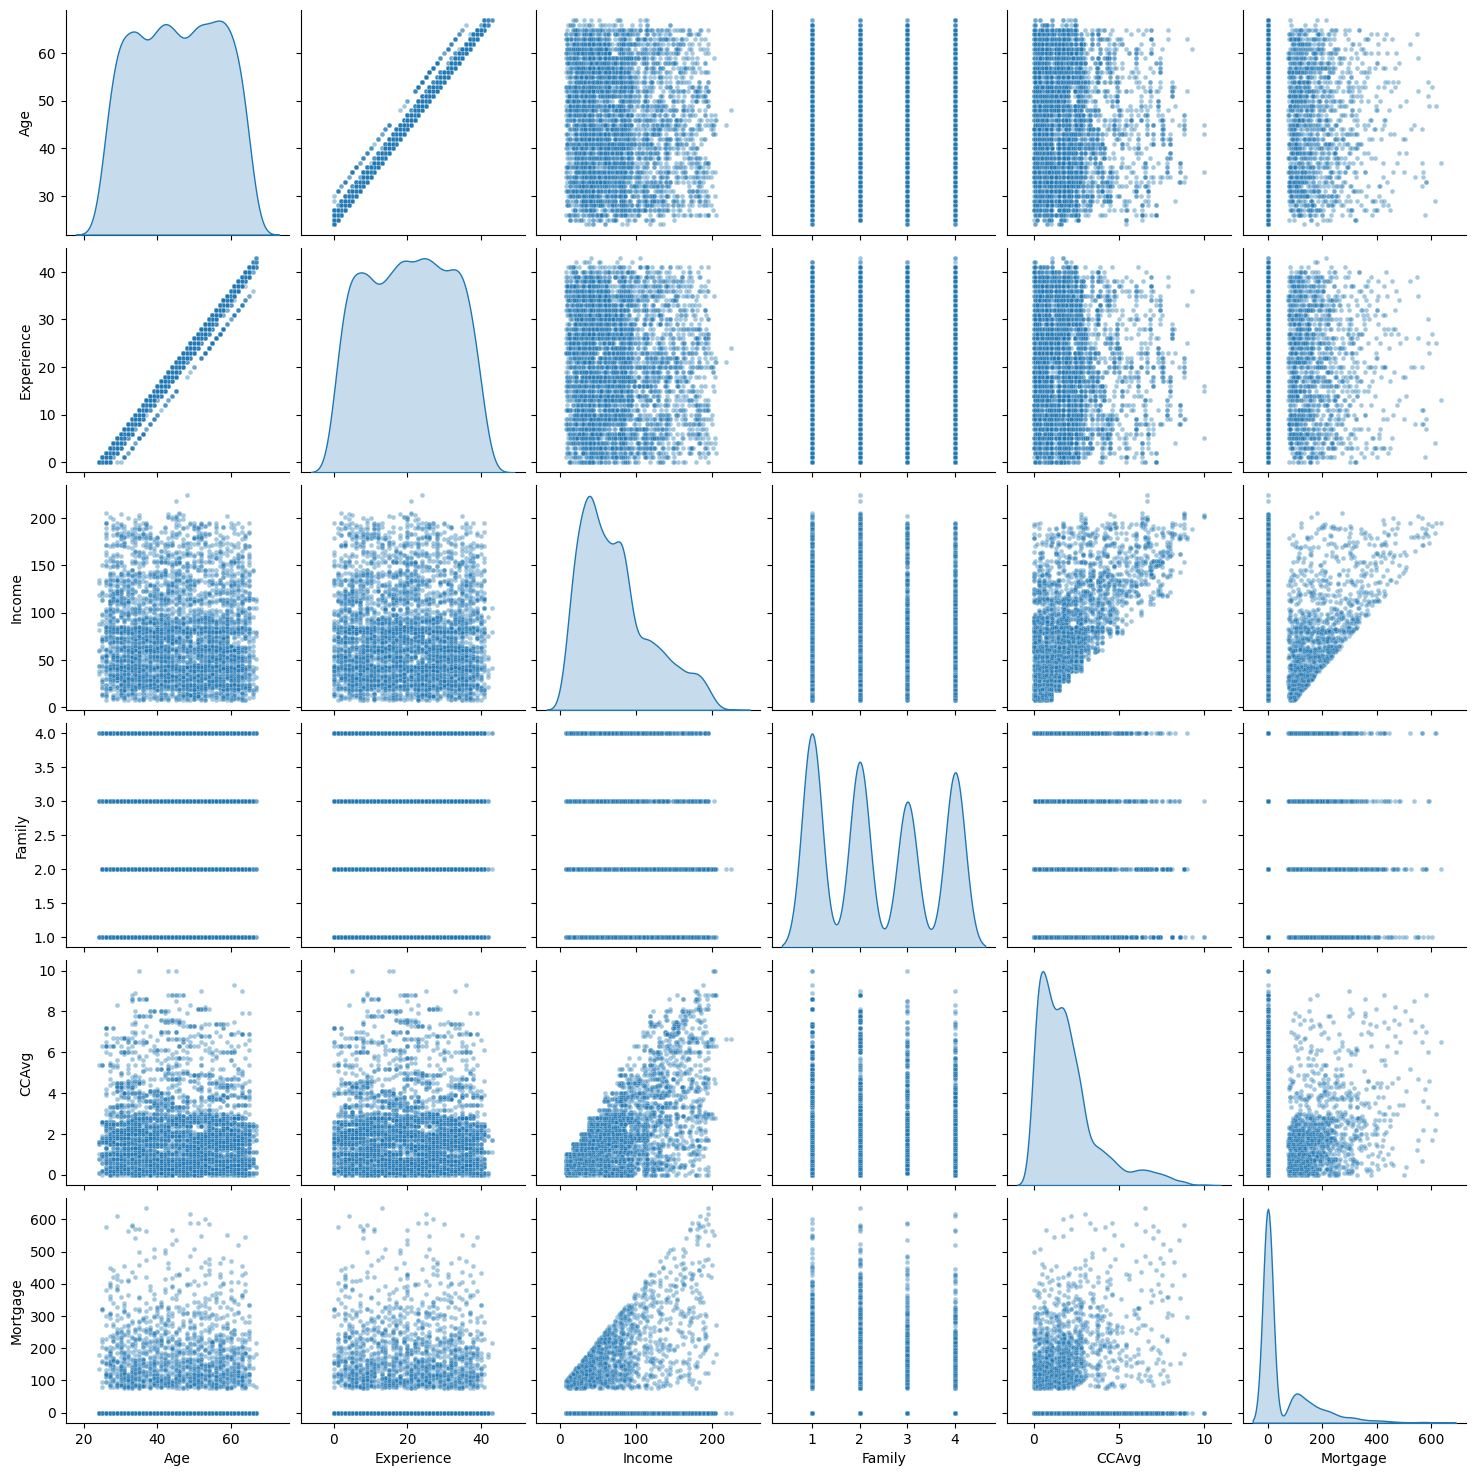

In [157]:
sns.pairplot(loan_df[num_cols], diag_kind="kde", plot_kws={"alpha": 0.4, "s": 12})
plt.show()

### Par seleccionado: `Age` vs `Experience`

Se elige este par porque es el de relación más evidente en la matriz de dispersión. Los puntos forman una franja diagonal muy estrecha con pendiente positiva: a mayor edad, mayor experiencia laboral, de forma prácticamente lineal. Tiene sentido, porque la experiencia se acumula con los años de vida (aproximadamente, `Experience` ≈ `Age` - 25). La franja tiene un ancho pequeño y constante porque la edad a la que cada cliente empezó a trabajar varía poco.


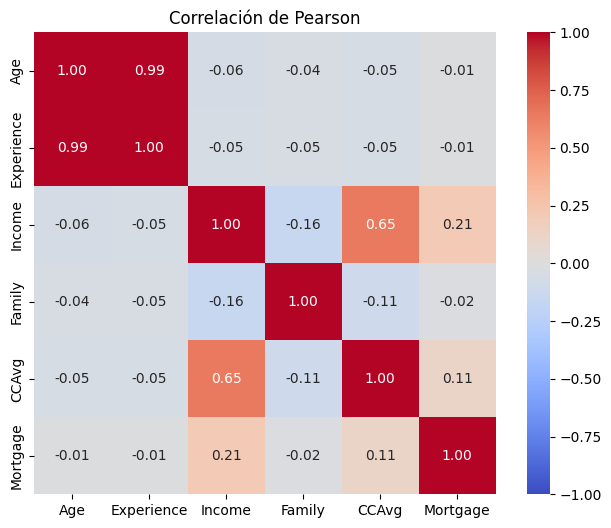

In [158]:
corr = loan_df[num_cols].corr(method="pearson")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlación de Pearson")
plt.show()

### Correspondencia entre el gráfico y el coeficiente

Para `Age` y `Experience` el coeficiente de Pearson es **r = 0.99**. Es positivo y muy cercano a 1, lo que coincide con la franja diagonal estrecha observada en el diagrama de dispersión. Por tanto, el valor numérico se corresponde con lo esperado: la relación es lineal, positiva y muy fuerte.



10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


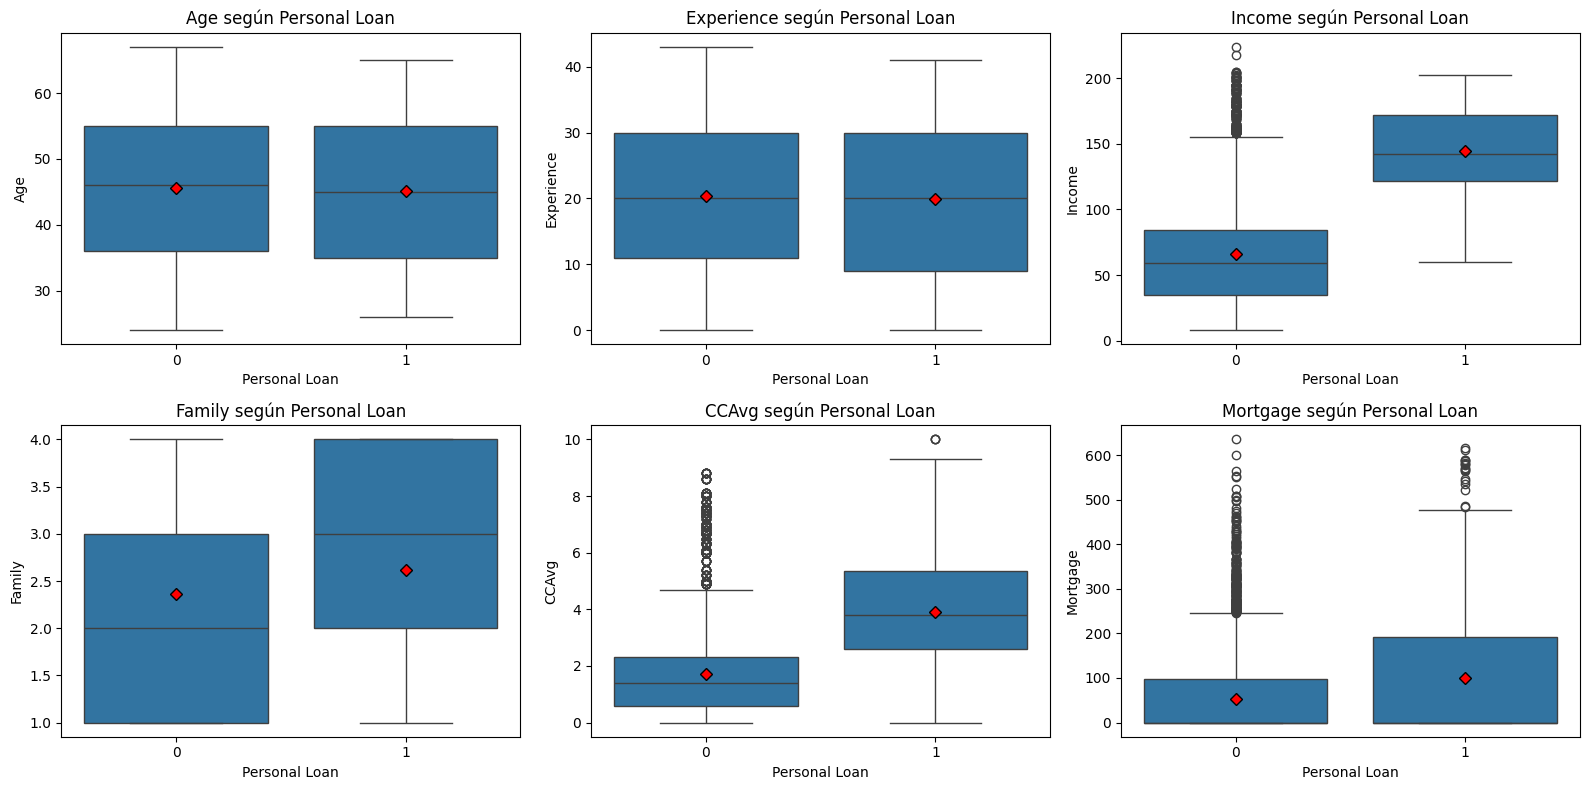

In [159]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=loan_df, x="Personal Loan", y=col, showmeans=True, ax=ax,
                meanprops={"marker": "D", "markerfacecolor": "red", "markeredgecolor": "black"})
    ax.set_title(f"{col} según Personal Loan")
plt.tight_layout()
plt.show()

### Hallazgo en variables numéricas

**`Income` es la variable que más separa a los dos grupos.** La mediana de los clientes que aceptaron el préstamo (`Personal Loan` = 1) es de aproximadamente 142 mil USD, frente a cerca de 60 mil USD en quienes no lo aceptaron. Además, la caja del grupo 1 (aprox. 120 a 172) casi no se traslapa con la del grupo 0 (aprox. 35 a 85): el cuartil inferior de quienes aceptaron queda por encima del cuartil superior de quienes no. Los puntos atípicos del grupo 0 (ingresos de 160 a 224) muestran que hay clientes de ingreso alto que no aceptaron, así que el ingreso es un fuerte indicio de aceptación pero no una regla.

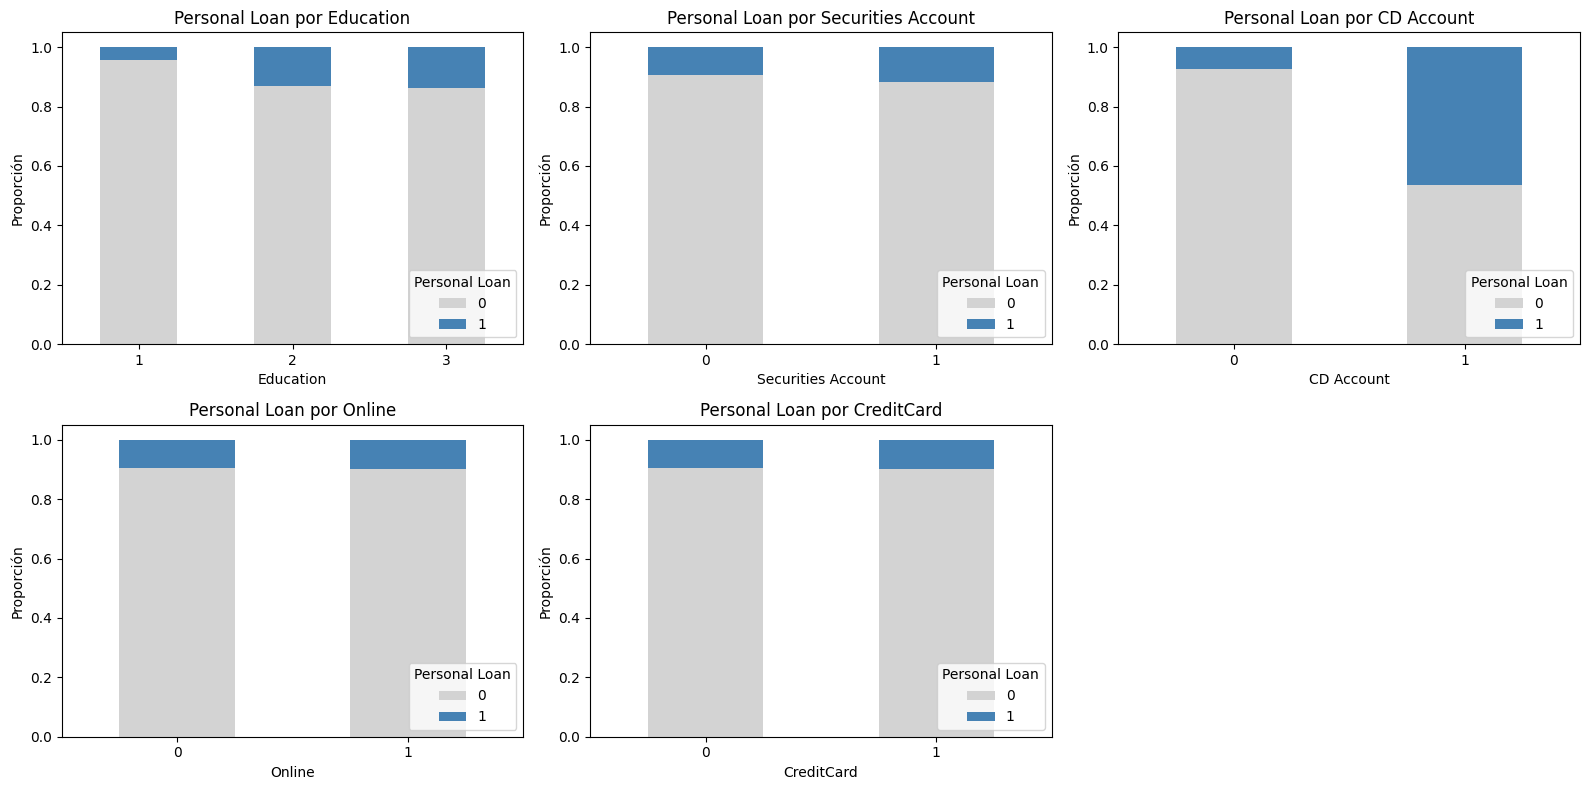

In [160]:
cat_sin_zip = [c for c in cat_cols if c not in ["ZIP Code", "Personal Loan"]]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cat_sin_zip):
    prop = pd.crosstab(loan_df[col], loan_df["Personal Loan"], normalize="index")
    prop.plot(kind="bar", stacked=True, ax=ax, color=["lightgray", "steelblue"])
    ax.set_title(f"Personal Loan por {col}")
    ax.set_ylabel("Proporción")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Personal Loan", loc="lower right")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

### Hallazgo en variables categóricas

**`CD Account` muestra el patrón más marcado.** Entre quienes tienen cuenta de certificado de depósito, cerca del 46 % aceptó el préstamo, frente a aproximadamente el 7 % entre quienes no la tienen. La proporción de aceptación es unas seis veces mayor en el primer grupo, y es la única variable categórica en la que la barra azul (`Personal Loan` = 1) se acerca a la mitad de la barra.

**`Education` también se asocia con la aceptación, pero con un salto único.** El nivel 1 tiene la tasa más baja (aprox. 4 %), mientras que los niveles 2 y 3 tienen tasas similares y más altas (aprox. 13 % y 14 %). Es decir, la aceptación no crece de forma progresiva con cada nivel, sino que los clientes con estudios superiores al nivel 1 aceptan unas tres veces más.

---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/

---